<a href="https://colab.research.google.com/github/Olya-Shulga/Univercity/blob/main/data_mining/%D0%94%D0%9F%D0%9E_%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%961__%D0%A0%D0%B0%D0%B7%D0%B2%D0%B5%D0%B4%D0%BE%D1%87%D0%BD%D1%8B%D0%B9_%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7%2C_%D0%BF%D1%80%D0%B5%D0%B4%D0%BE%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85_%D0%B8_%D0%BF%D0%BE%D1%81%D1%82%D1%80%D0%BE%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №1. Разведочный анализ, предобработка данных и построение модели классификации *(на примере датасета Bank Marketing)***

---

## **Введение**


**Цель работы:** Обучить модель машинного обучения для предсказания, откроет ли клиент банка срочный вклад по результатам маркетинговой кампании (целевая переменная `y`: "yes" — откроет, "no" — не откроет).


**Датасет:** [Bank Marketing Dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing) — данные о маркетинговых кампаниях португальского банка.



**Что вы научитесь делать:**
- Загружать и исследовать данные
- Выявлять проблемы через разведочный анализ (EDA)
- Анализировать и обрабатывать пропущенные значения
- Формулировать и проверять гипотезы
- Создавать новые признаки (Feature Engineering)
- Сравнивать стратегии и выбирать лучшую модель

---

## **Часть 1. Настройка окружения**

> 📚 **Подсказка:** Аналогичная настройка рассматривалась в [**Занятии 1, Часть 1** и **Занятии 2, Часть 1**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=5f49d9aa).

In [17]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Настройки отображения
sns.set_style("whitegrid")
pd.set_option('display.max_columns', 20)

---

## **Часть 2. Загрузка и первичный осмотр данных**

> 📚 **Подсказка:** Методы первичного осмотра (`head()`, `info()`, `describe()`, `shape`) подробно разобраны в [**Занятии 1, Часть 3.2**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=9ef7543b) и [**Занятии 2, Часть 2.1**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=43b439e3).

### **Задание 2.1. Загрузите датасет**

In [18]:
# Загрузка датасета Bank Marketing
url = "https://raw.githubusercontent.com/rishabhathiya/Bank-Marketing/refs/heads/main/bank.csv"
bank = pd.read_csv(url, sep=';')

# ВАЖНО: В этом датасете пропуски записаны как "unknown"
# Заменяем их на NaN, чтобы isna() корректно их определял
bank = bank.replace('unknown', np.nan)

bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,NaN,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,NaN,3,jun,199,4,-1,0,NaN,no
4,59,blue-collar,married,secondary,no,0,yes,no,NaN,5,may,226,1,-1,0,NaN,no


### **Задание 2.2. Изучите структуру данных**

**1. Выведите размерность датасета:**

In [19]:
print(f"Размер датасета: {bank.shape[0]} строк, {bank.shape[1]} столбцов")

Размер датасета: 4521 строк, 17 столбцов


**2. Отобразите первые 10 строк датасета**

In [20]:
bank.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,NaN,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,NaN,3,jun,199,4,-1,0,NaN,no
4,59,blue-collar,married,secondary,no,0,yes,no,NaN,5,may,226,1,-1,0,NaN,no
5,35,management,single,tertiary,no,747,no,no,cellular,23,feb,141,2,176,3,failure,no
6,36,self-employed,married,tertiary,no,307,yes,no,cellular,14,may,341,1,330,2,other,no
7,39,technician,married,secondary,no,147,yes,no,cellular,6,may,151,2,-1,0,NaN,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,NaN,14,may,57,2,-1,0,NaN,no
9,43,services,married,primary,no,-88,yes,yes,cellular,17,apr,313,1,147,2,failure,no


**3. Выведите информацию о типах данных и пропусках**

In [21]:
bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4483 non-null   object
 2   marital    4521 non-null   object
 3   education  4334 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    3197 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   816 non-null    object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


**4. Выведите статистику числовых признаков**


In [22]:
bank.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


**5. Выведите названия всех столбцов в виде списка строк**

In [23]:
list(bank.columns)

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

### **Задание 2.3. Ответьте на вопросы**

---

> 📝 **Как отвечать на текстовые вопросы?** Дважды кликните на ячейку → впишите ответ → нажмите `Shift+Enter`

---


**Вопрос 1:** Сколько записей (клиентов) в датасете?

**Ответ:**  `4521`

**Вопрос 2:** Сколько признаков (столбцов)?


**Ответ:** `17`

**Вопрос 3:** Какая переменная является целевой (что предсказываем)?


**Ответ:** `y — целевая переменная, показывающая, оформил ли клиент банковский депозит (yes или no)`


**Вопрос 4:** Какие типы данных преобладают — числовые или категориальные?

**Ответ:** `Категориальные. В датасете 10 столбцов типа object и 7 столбцов типа int64`

---

### **Описание столбцов датасета Bank Marketing**

| Столбец | Описание | Тип |
|---------|----------|-----|
| `age` | Возраст клиента | Числовой |
| `job` | Тип занятости | Категориальный |
| `marital` | Семейное положение | Категориальный |
| `education` | Уровень образования | Категориальный |
| `default` | Есть ли дефолт по кредиту | Категориальный |
| `balance` | Баланс на счёте (евро) | Числовой |
| `housing` | Есть ли ипотека | Категориальный |
| `loan` | Есть ли личный кредит | Категориальный |
| `contact` | Тип связи | Категориальный |
| `day` | День последнего контакта | Числовой |
| `month` | Месяц последнего контакта | Категориальный |
| `duration` | Длительность последнего звонка (сек) | Числовой |
| `campaign` | Кол-во контактов в этой кампании | Числовой |
| `pdays` | Дней с последнего контакта (-1 = не было) | Числовой |
| `previous` | Кол-во контактов до этой кампании | Числовой |
| `poutcome` | Результат прошлой кампании | Категориальный |
| `y` | **Целевая переменная:** открыл ли вклад | Категориальный |

---

## **Часть 3. Разведочный анализ данных (EDA)**

> 📚 **Подсказка:** Цель EDA — выявить проблемы в данных и найти закономерности (паттерны). Методология описана в [**Занятии 2, Часть 2**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=29f19e7a).

### **3.1. Анализ целевой переменной (баланс классов)**

> 📚 **Подсказка:** Анализ баланса классов рассмотрен в [**Занятии 2, Часть 2.3**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=15c684d7).

In [24]:
# Создаём числовую версию целевой переменной в столбце target
bank['target'] = (bank['y'] == 'yes').astype(int)

bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,target
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,NaN,no,0
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no,0
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no,0
3,30,management,married,tertiary,no,1476,yes,yes,NaN,3,jun,199,4,-1,0,NaN,no,0
4,59,blue-collar,married,secondary,no,0,yes,no,NaN,5,may,226,1,-1,0,NaN,no,0


**Подсчитайте распределение целевой переменной 'y'**

In [25]:
# Используйте value_counts()
bank['y'].value_counts()

,count
y,
no,4000
yes,521


**Вопрос:** сколько клиентов открыли депозит (yes)? сколько не открыли (no)?



**Ответ:** `521 - открыли депозит, 4000 - не открыли депозит`

---

**Визуализируйте распределения классов графически (постройте столбчатую (barplot) или круговую (pie chart) диаграмму)**


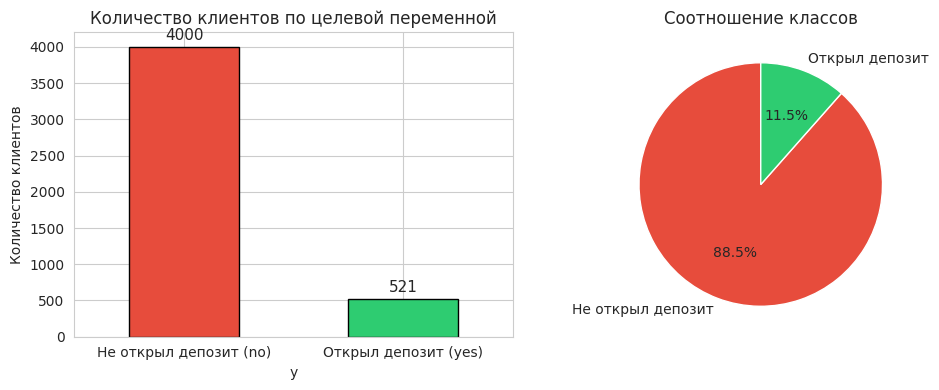

In [26]:
# Используйте sns.countplot() или value_counts().plot(kind='bar')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Создаём фигуру с двумя графиками в ряд

colors = ['#e74c3c', '#2ecc71']  # Красный для "no", зелёный для "yes"

deposit_counts = bank['y'].value_counts().reindex(['no', 'yes'])  # Считаем количество клиентов по классам

deposit_counts.plot(
    kind='bar',
    ax=axes[0],
    color=colors,
    edgecolor='black'
)  # Столбчатая диаграмма слева

axes[0].set_title('Количество клиентов по целевой переменной')  # Заголовок левого графика
axes[0].set_ylabel('Количество клиентов')  # Подпись оси Y
axes[0].set_xticklabels(
    ['Не открыл депозит (no)', 'Открыл депозит (yes)'],
    rotation=0
)  # Подписи столбиков

for i, v in enumerate(deposit_counts):  # Проходим по каждому значению
    axes[0].text(
        i,
        v + 100,
        str(v),
        ha='center',
        fontsize=11
    )  # Добавляем количество над столбиком

deposit_counts.plot(
    kind='pie',
    ax=axes[1],
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    labels=['Не открыл депозит', 'Открыл депозит']
)  # Круговая диаграмма справа

axes[1].set_title('Соотношение классов')  # Заголовок правого графика
axes[1].set_ylabel('')  # Убираем подпись оси Y

plt.tight_layout()  # Автоматически подгоняем отступы
plt.show()  # Отображаем графики

---

**Вычислите процент клиентов, открывших вклад**

In [27]:
opened_percent = (bank['y'] == 'yes').mean() * 100
print(f"Процент клиентов, открывших вклад: {opened_percent:.2f}%")

Процент клиентов, открывших вклад: 11.52%


**Вопрос:** Сбалансированы ли классы? Какой класс преобладает?

**Ответ:** `Классы не сбалансировны. Большинство людей не открыло вклад`

---

### **3.2. Анализ пропущенных значений**

> 📚 **Подсказка:** Проверка пропусков с помощью `isna().sum()` показана в [**Занятии 1, Часть 3.6**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=1f244634) и [**Занятии 2, Часть 2.2**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=e96e5f15).

**Проверьте наличие пропущенных значений в датасете с помощью `isna().sum()`**

In [28]:
missing_count = bank.isna().sum().sort_values(ascending=False)
missing_count

,0
poutcome,3705
contact,1324
education,187
job,38
age,0
default,0
balance,0
housing,0
loan,0
marital,0


**Вычислите процент пропущенных значений в каждом столбце датасета**

In [29]:
missing_percent = (bank.isna().mean() * 100).sort_values(ascending=False)
missing_percent


,0
poutcome,81.950896
contact,29.285556
education,4.136253
job,0.840522
age,0.000000
default,0.000000
balance,0.000000
housing,0.000000
loan,0.000000
marital,0.000000


**Постройте столбчатую диаграмму (`barplot`) для визуализации процента пропусков**

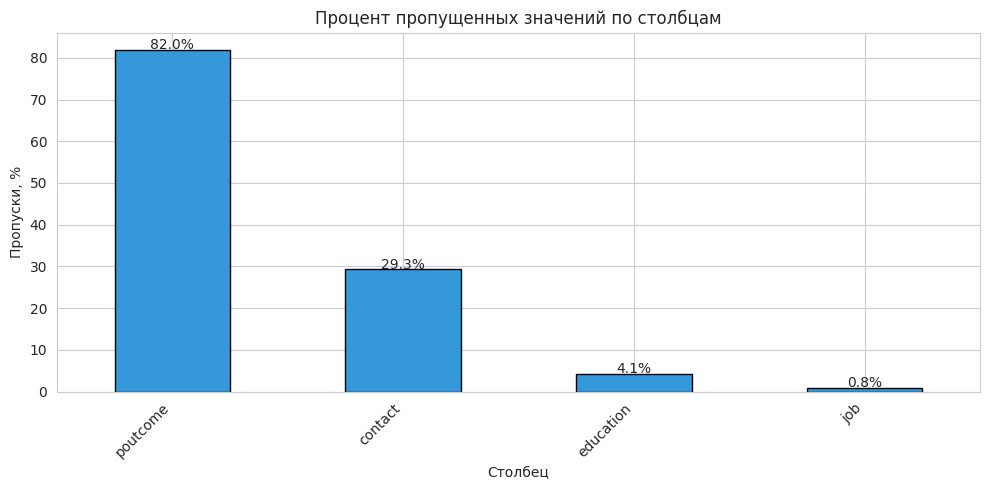

In [30]:
missing_percent_plot = missing_percent[missing_percent > 0]  # Оставляем только столбцы, где есть пропуски

fig, ax = plt.subplots(figsize=(10, 5))  # Создаём фигуру для одного графика

missing_percent_plot.plot(
    kind='bar',
    ax=ax,
    color='#3498db',
    edgecolor='black'
)  # Строим столбчатую диаграмму

ax.set_title('Процент пропущенных значений по столбцам')  # Заголовок графика
ax.set_xlabel('Столбец')  # Подпись оси X
ax.set_ylabel('Пропуски, %')  # Подпись оси Y

ax.set_xticklabels(
    missing_percent_plot.index,
    rotation=45,
    ha='right'
)  # Поворачиваем названия столбцов для удобства чтения

for i, v in enumerate(missing_percent_plot):  # Проходим по каждому значению
    ax.text(
        i,
        v + 0.2,
        f'{v:.1f}%',
        ha='center',
        fontsize=10
    )  # Добавляем процент над каждым столбиком

plt.tight_layout()  # Автоматически подгоняем отступы
plt.show()  # Отображаем график

**Вопрос:** В каких столбцах больше всего пропусков? Какой процент данных потеряем, если удалим все строки с пропусками?





**Ответ:** `Больше всего пропусков содержится в столбце poutcome — около 82% данных. Далее идут contact — 29,3%, education — 4,1% и job — 0,8%. Если удалить все строки с любым пропуском, мы потеряем как минимум 82% строк`



---

### **3.3. Анализ числовых признаков**

> 📚 **Подсказка:** Построение гистограмм с разбивкой по целевой переменной (`hue`) показано в [**Занятии 2, Часть 2.4**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=ea28aa58).



**Обязательно постройте гистограммы для следующих признаков:**
- `age` — возраст
- `balance` — баланс на счёте  
- `duration` — длительность звонка

**Постройте гистограммы для числовых признаков с разбивкой по целевой переменной**

> Используйте `sns.histplot()` с параметром `hue='target'`

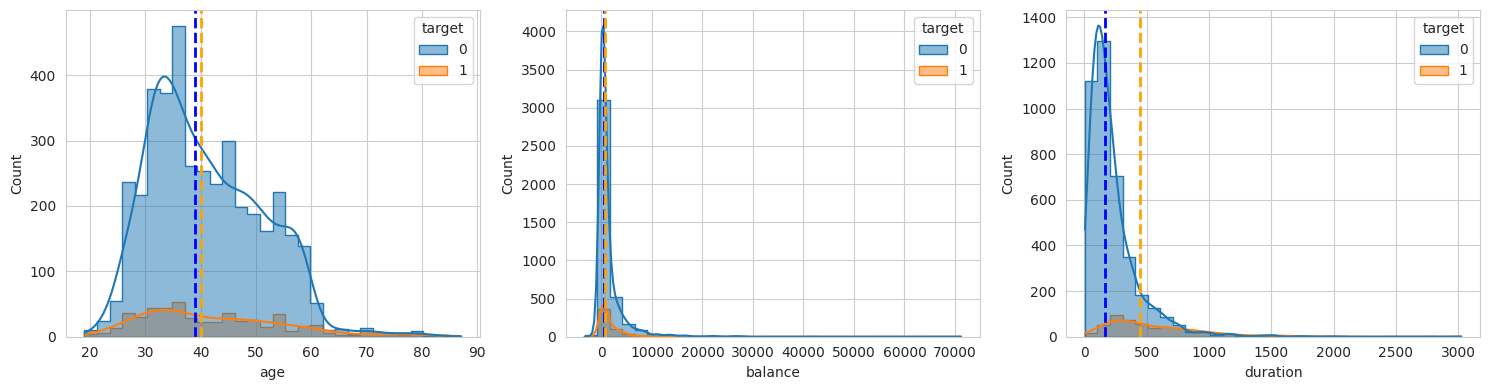

In [31]:
numeric_features = ['age', 'balance', 'duration']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numeric_features):
    # ВАШ КОД: постройте гистограмму для col на axes[i]
    # Строим распределение признака для двух классов
    sns.histplot(
        data=bank,
        x=col,
        hue='target',
        kde=True,
        bins=30,
        element='step',
        alpha=0.5,
        ax=axes[i]
    )

    # Вычисляем медиану для клиентов, которые не открыли депозит
    median_0 = bank[bank['target'] == 0][col].median()

    # Вычисляем медиану для клиентов, которые открыли депозит
    median_1 = bank[bank['target'] == 1][col].median()

    # Добавляем медиану класса 0 на график
    axes[i].axvline(
        median_0,
        color='blue',
        linestyle='--',
        linewidth=2
    )

    # Добавляем медиану класса 1 на график
    axes[i].axvline(
        median_1,
        color='orange',
        linestyle='--',
        linewidth=2
    )

plt.tight_layout()
plt.show()

*(При желании, можете не использовать мои шаблоны, а написать код для построения графиков с нуля и самостоятельно)*

**Вопрос:** Какие наблюдения вы можете сделать? Какие признаки различаются для клиентов, открывших и не открывших вклад?



**Ответ:** `Наиболее заметные различия наблюдаются для признака duration. У клиентов, открывших депозит (target = 1), медианная длительность разговора значительно выше, чем у клиентов, которые депозит не открыли (target = 0). Для признака age медианы практически совпадают, поэтому существенного различия между группами по возрасту не наблюдается. Для balance медианы также расположены близко друг к другу, хотя у клиентов, открывших депозит, медианный баланс немного выше. Таким образом, с открытием депозита связан duration`



---

### **Задание 3.4. Анализ категориальных признаков**

> 📚 **Подсказка:** Построение столбчатой диаграммы (`barplot`) для анализа связи категориальных признаков с целевой переменной показано в [**Занятии 2, Часть 2.5**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=ea6a781f).



**Постройте графики для анализа доли открывших депозит по категориальным признакам ('job', 'marital', 'education', 'contact'):**

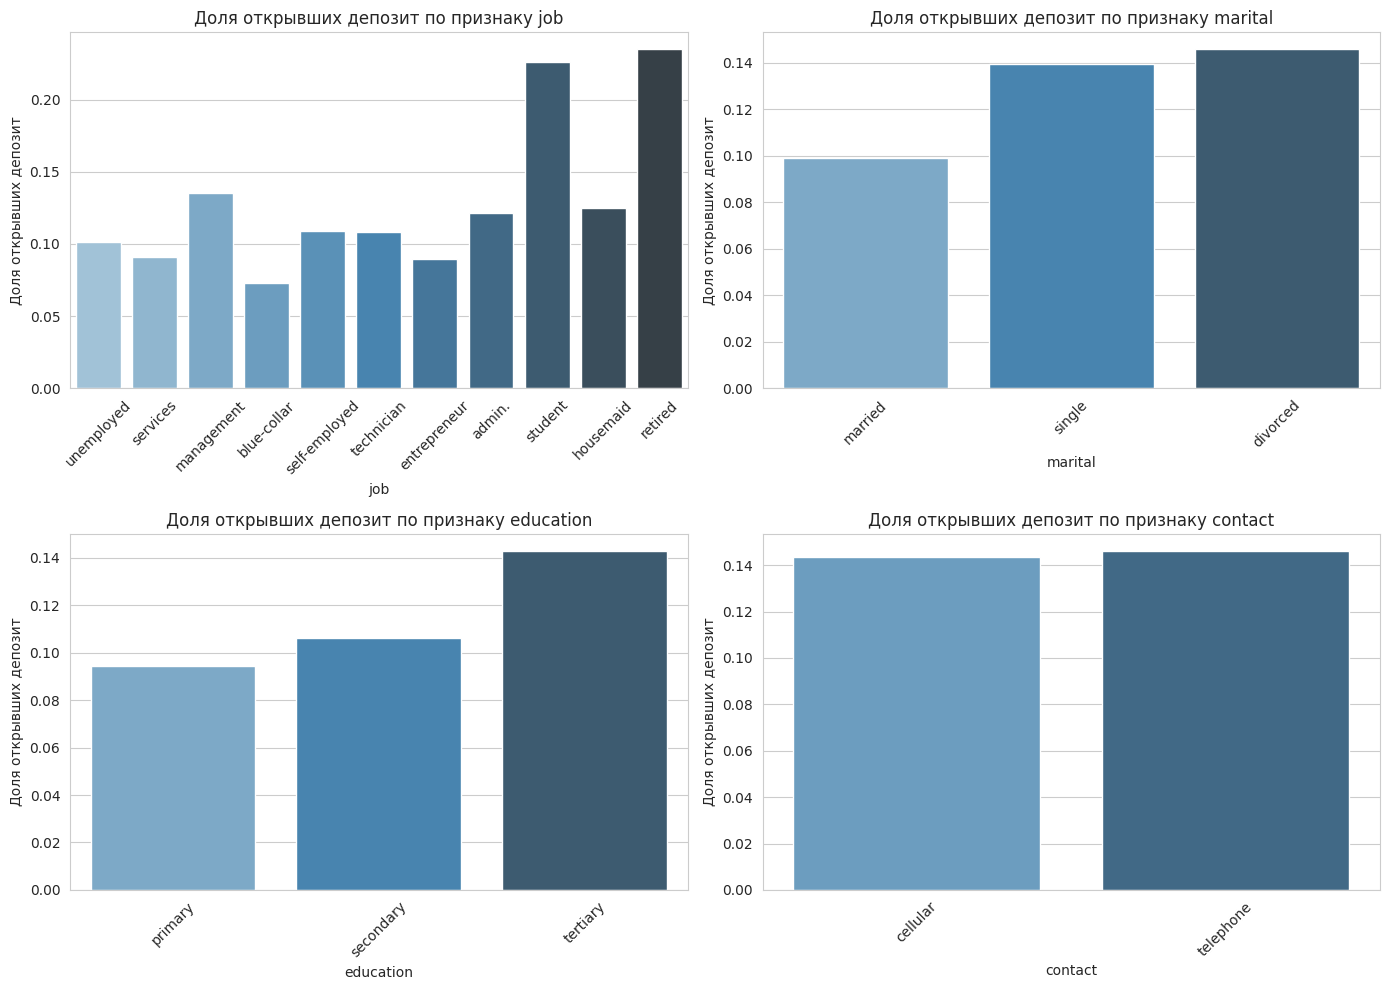

In [32]:
cat_features = ['job', 'marital', 'education', 'contact']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    # ВАШ КОД: постройте barplot для col на axes[i]
    # Используйте sns.barplot(data=bank, x=col, y='target', ax=axes[i])
    # Добавьте plt.xticks(rotation=45) для поворота подписей
    sns.barplot(data=bank, x=col, y='target', ax=axes[i], hue=col,
                palette='Blues_d', legend=False, errorbar=None)
    axes[i].set_title(f'Доля открывших депозит по признаку {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Доля открывших депозит')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

---

**Ответьте на вопросы:**


**Вопрос:** Люди каких профессий чаще открывают депозит?



**Ответ:** `Чаще всего депозит открывают пенсионеры (retired) и студенты (student). Среди остальных профессий доля открытия депозита заметно ниже; следующей выделяется категория management`



**Вопрос:** Влияет ли семейное положение на вероятность открытия депозита?


**Ответ:** `Семейное положение связано с вероятностью открытия депозита. Наибольшая доля открывших депозит наблюдается среди разведённых (divorced), немного ниже среди не состоящих в браке (single). Среди состоящих в браке (married) доля ниже`



**Вопрос:** Какой тип связи (contact) наиболее эффективен?



**Ответ:** `Доля открывших депозит немного выше при контакте по телефону (telephone), чем при мобильной связи (cellular). Однако различие очень небольшое, поэтому нельзя говорить о существенном преимуществе одного типа связи`



**Вопрос:** Какие в общем категории клиентов чаще открывают вклад (примерный портрет по всем категориальным признакам в совокупности)?



**Ответ:** `По рассмотренным категориальным признакам чаще открывают депозит пенсионеры и студенты, разведённые или не состоящие в браке клиенты, а также клиенты с высшим уровнем образования (tertiary). Тип связи существенной разницы практически не показывает: доля открытия депозита при telephone и cellular близка`



---

### **Задание 3.5. Анализ связей между признаками (Boxplot)**

> 📚 **Подсказка:** Использование boxplot для анализа распределений показано в [**Занятии 2, Часть 2.6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=592b07cc).

**Постройте `boxplot` для анализа баланса по уровню образования**

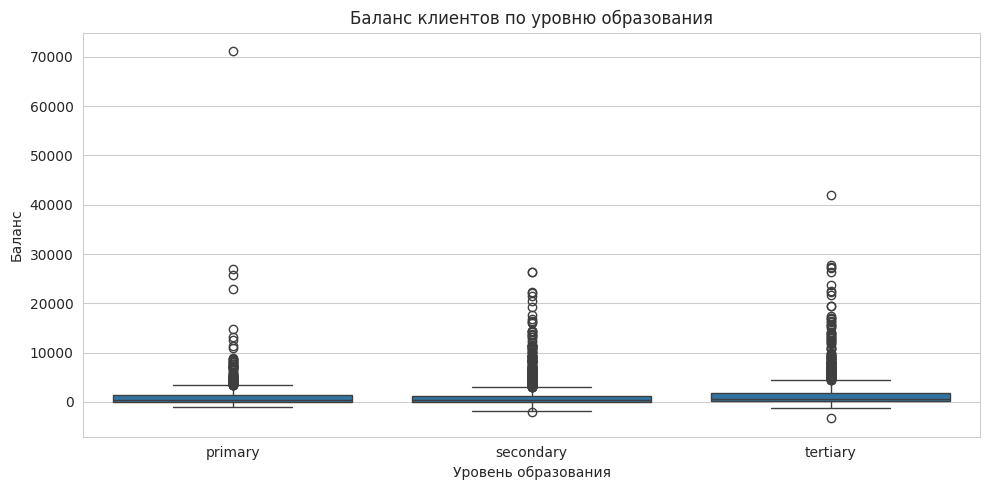

In [33]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bank, x='education', y='balance')
plt.title('Баланс клиентов по уровню образования')
plt.xlabel('Уровень образования')
plt.ylabel('Баланс')
plt.tight_layout()
plt.show()

**Вопрос:** Различается ли баланс у клиентов с разным образованием?



**Ответ:** `Баланс клиентов немного различается в зависимости от уровня образования. У клиентов с высшим образованием (tertiary) медианный баланс визуально выше, чем у клиентов с primary и secondary образованием. При этом распределения сильно перекрываются, а во всех группах наблюдается большое количество выбросов, поэтому образование само по себе не даёт чёткого разделения клиентов по балансу`



---

### **Задание 3.6. Группировка данных**

> 📚 **Подсказка:** Метод `groupby()` подробно разобран в [**Занятии 1, Часть 3.7**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=baa512e4).

**Вычислите средний баланс и долю открывших депозит по типу работы**

In [34]:
job_stats = (
    bank.groupby('job', dropna=False)
        .agg(
            mean_balance=('balance', 'mean'),
            deposit_rate=('target', 'mean'),
            clients=('target', 'size')
        )
        .sort_values('deposit_rate', ascending=False)
)

job_stats

,mean_balance,deposit_rate,clients
job,,,
retired,2319.191304,0.234783,230
student,1543.821429,0.226190,84
NaN,1501.710526,0.184211,38
management,1766.928793,0.135191,969
housemaid,2083.803571,0.125000,112
admin.,1226.736402,0.121339,478
self-employed,1392.409836,0.109290,183
technician,1330.996094,0.108073,768
unemployed,1089.421875,0.101562,128


**Вычислите долю открывших депозит по уровню образования**

In [35]:
education_stats = (
    bank.groupby('education', dropna=False)['target']
        .mean()
        .sort_values(ascending=False)
)

education_stats

,target
education,
tertiary,0.142963
secondary,0.106245
NaN,0.101604
primary,0.094395


---

## **Часть 4. Формулировка гипотез**

> 📚 **Подсказка:** Формулировка гипотез на основе EDA описана в [**Занятии 2, Часть 3**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=329f49e7).



На основе проведённого EDA сформулируйте **минимум 3 гипотезы** о том, какие признаки и преобразования могут улучшить модель.

### **Ваши гипотезы:**

(Дважды нажмите правой кнопкой мыши на ячеку ниже, чтобы вписать свои гипотезы)

| № | Наблюдение из EDA | Гипотеза | Как проверить |
|---|-------------------|----------|---------------|
| 1 | `duration` заметно различается у клиентов, открывших и не открывших депозит | `duration` является важным признаком для предсказания | Сравнить accuracy модели с `duration` и без него |
| 2 | `pdays = -1` означает, что с клиентом ранее не контактировали | Бинарный признак `was_contacted` может улучшить модель | Создать `was_contacted` и сравнить accuracy с baseline |
| 3 | В `job`, `education`, `contact` и `poutcome` имеются пропуски | Сам факт наличия пропуска может быть информативен | Создать признаки `*_unknown` и сравнить accuracy с baseline |



**Примеры формулировок (для ориентира):**

| Наблюдение | Гипотеза | Как проверить |
|------------|----------|---------------|
| `duration` сильно различается у классов | Признак важен для предсказания | Сравнить accuracy с `duration` и без него |
| `pdays` = -1 означает "не контактировали" | Создать бинарный признак `was_contacted` | Создать признак, сравнить accuracy |
| `balance` имеет отрицательные значения | Создать признак `has_positive_balance` | Создать признак, сравнить accuracy |
| В `job` есть пропуски | Факт пропуска может быть информативен | Создать `job_unknown`, сравнить accuracy |
| В `education` есть пропуски | Заполнение модой лучше удаления строк | Сравнить стратегии обработки пропусков |
| В `contact` много пропусков | Признак `contact_unknown` улучшит модель | Добавить признак, сравнить accuracy |
| Много категориальных признаков | One-Hot Encoding улучшит модель | `pd.get_dummies()`, сравнить accuracy |

**Примеры кода для проверки гипотез: (пригодится в следующем пункте)**

> 📚 **Подсказка:** Методология проверки гипотез через эксперименты подробно разобрана в [**Занятии 2, Часть 6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=28a74583).



**Проверка гипотезы: важность признака `duration`**

```python
# С duration
cols_with_duration = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
accuracy_with = evaluate_model(df[cols_with_duration], df['target'])

# Без duration
cols_without_duration = ['age', 'balance', 'campaign', 'pdays', 'previous']
accuracy_without = evaluate_model(df[cols_without_duration], df['target'])

print(f"С duration:    {accuracy_with:.4f}")
print(f"Без duration:  {accuracy_without:.4f}")
print(f"Разница:       {accuracy_with - accuracy_without:+.4f}")
```



**Проверка гипотезы: информативность пропуска в `job`**

```python
# Проверяем: различается ли доля положительного класса?
print("Доля открывших вклад по группам:")
print(bank.groupby(bank['job'].isna())['target'].mean())

# Если доли сильно различаются → признак потенциально полезен
```



---

## **Часть 5. Базовая (baseline) модель**

> 📚 **Подсказка:** Создание baseline модели с использованием только числовых признаков описано в [**Занятии 2, Часть 4**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=47225a7d).

**Baseline** — простейшая работающая модель, с которой мы будем сравнивать все улучшения.

### **5.1. Вспомогательная функция**

> 📚 **Подсказка:** Функция `evaluate_model()` создана в [**Занятии 2, после Части 4.6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=maxKagcsxhv8).

In [36]:
def evaluate_model(X, y):
    """
    Обучает логистическую регрессию и возвращает accuracy.
    """
    # 1. Разделение данных (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # 2. Масштабирование (ВАЖНО: fit только на train!)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 3. Обучение модели
    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_train_scaled, y_train)

    # 4. Предсказание и оценка
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    return accuracy

### **5.2. Подготовка данных для baseline**

In [37]:
# Выбираем только числовые признаки для baseline
numeric_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

# Подготовьте X и y
X_baseline = bank[numeric_cols]
y_baseline = bank['target']

print(f"Размер X: {X_baseline.shape}")
print(f"Размер y: {y_baseline.shape}")

Размер X: (4521, 7)
Размер y: (4521,)


### **5.3. Обучите базовую (baseline) модель**

<details>
<summary><b>Пример кода:</b></summary>



```python
# Обучите baseline и сохраните результат
accuracy_baseline = evaluate_model(X_baseline, y_baseline)

# Словарь для хранения результатов экспериментов
results = {}
results['baseline'] = {'accuracy': accuracy_baseline, 'n_features': len(numeric_cols)}

print("=" * 50)
print("BASELINE МОДЕЛЬ")
print("=" * 50)
print(f"Признаки: {numeric_cols}")
print(f"Количество признаков: {len(numeric_cols)}")
print(f"Accuracy: {accuracy_baseline:.4f} ({accuracy_baseline:.1%})")
print("=" * 50)

```



In [38]:
# Обучите baseline и сохраните результат
accuracy_baseline = evaluate_model(X_baseline, y_baseline)

# Словарь для хранения результатов экспериментов
results = {}
results['baseline'] = {'accuracy': accuracy_baseline, 'n_features': len(numeric_cols)}

print("=" * 50)
print("BASELINE МОДЕЛЬ")
print("=" * 50)
print(f"Признаки: {numeric_cols}")
print(f"Количество признаков: {len(numeric_cols)}")
print(f"Accuracy: {accuracy_baseline:.4f} ({accuracy_baseline:.1%})")
print("=" * 50)

BASELINE МОДЕЛЬ
Признаки: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Количество признаков: 7
Accuracy: 0.8862 (88.6%)


---

## **Часть 6. Стратегии обработки пропусков**

> 📚 **Подсказка:** Стратегии заполнения пропусков (удаление, заполнение модой/медианой, создание признаков) подробно разобраны в [**Занятии 2, Часть 5**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=89cec4d9).

### **6.1. Стратегия A: Удаление строк с пропусками**

In [39]:
# Посмотрим, сколько данных потеряем
df_dropped = bank.dropna()

print(f"Было строк: {len(bank)}")
print(f"Стало строк: {len(df_dropped)}")
print(f"Потеряно: {len(bank) - len(df_dropped)} ({(len(bank) - len(df_dropped)) / len(bank) * 100:.1f}%)")

Было строк: 4521
Стало строк: 764
Потеряно: 3757 (83.1%)


**Вопрос:** Приемлемо ли терять столько данных?



**Ответ:** `Нет, терять 83,1% данных неприемлемо. После удаления строк с пропусками из 4521 записи останется только 764, то есть будет потеряно 3757 строк. Это слишком большая часть выборки, поэтому лучше использовать другой способ обработки пропусков, например заполнение значений или создание дополнительных признаков, указывающих на наличие пропуска`

---

### **6.2. Стратегия B: Заполнение модой**

> 📚 **Подсказка:** Заполнение пропусков модой через `fillna()` рассматривалось в [**Занятии 2, Часть 5, Стратегия B**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=8e470458).

**Заполните категориальные пропуски модой (самым частым значением)**

In [41]:
df_filled = bank.copy()

cat_cols_with_na = ['job', 'education', 'contact', 'poutcome']

for col in cat_cols_with_na:
    if df_filled[col].isna().sum() > 0:
        # ВАШ КОД: найдите моду и заполните пропуски
        # mode_value = df_filled[col].mode()[0]
        # df_filled[col] = df_filled[col].fillna(mode_value)
        mode_value = df_filled[col].mode()[0]
        df_filled[col] = df_filled[col].fillna(mode_value)

print(f"Пропусков после заполнения: {df_filled.isna().sum().sum()}")

Пропусков после заполнения: 0


### **6.3. Стратегия C: Создание признаков из пропусков**

> 📚 **Подсказка:** Создание бинарных признаков из пропусков (например, `has_cabin` в Titanic) рассматривалось в [**Занятии 2, Часть 6, Эксперимент 2, Тест D**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=df9d9180).
>
> **Идея:** Сам факт того, что значение неизвестно, может быть информативен! Например: если клиент не указал профессию — это может что-то говорить о нём.

**Создайте признаки "был ли пропуск" ДО заполнения**

In [42]:
df_fe = bank.copy()

# Пример:
# df_fe['job_unknown'] = bank['job'].isna().astype(int)
# df_fe['education_unknown'] = bank['education'].isna().astype(int)
# df_fe['contact_unknown'] = bank['contact'].isna().astype(int)


# Создаём бинарные признаки: 1 — значение было пропущено, 0 — значение было известно
for col in ['job', 'education', 'contact', 'poutcome']:
    df_fe[f'{col}_unknown'] = bank[col].isna().astype(int)

print(df_fe[['job_unknown', 'education_unknown', 'contact_unknown', 'poutcome_unknown']].sum())

job_unknown            38
education_unknown     187
contact_unknown      1324
poutcome_unknown     3705
dtype: int64


**Проверим: различается ли доля положительного класса?**

In [43]:
print("Доля открывших вклад среди тех, у кого job неизвестен:")
print(df_fe.groupby('job_unknown')['target'].mean())

Доля открывших вклад среди тех, у кого job неизвестен:
job_unknown
0    0.114655
1    0.184211
Name: target, dtype: float64


**Вопрос:** Различается ли доля открывших вклад у клиентов с известной и неизвестной профессией?



**Ответ:** `Да, доля открывших вклад различается. Среди клиентов с неизвестной профессией вклад открыли около 18,4%, а среди клиентов с известной профессией — около 11,5%. Следовательно, сам факт отсутствия информации о профессии может быть информативным признаком для модели`



---

## **Часть 7. Feature Engineering**

> 📚 **Подсказка:** Создание новых признаков (Feature Engineering) подробно разобрано в [**Занятии 2, Часть 6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=28a74583).

### **7.1. Создайте новые признаки**

Создайте **минимум 3 новых признака** на основе ваших гипотез из Части 4.

<details>
<summary><b>Пример кода:</b></summary>

```python
df = bank.copy()

# Сначала создаём признаки из пропусков (ДО заполнения!)
df['job_unknown'] = bank['job'].isna().astype(int)
df['education_unknown'] = bank['education'].isna().astype(int)
df['contact_unknown'] = bank['contact'].isna().astype(int)

# Заполняем пропуски модой
for col in ['job', 'education', 'contact', 'poutcome']:
    if df[col].isna().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Пример признаков:
# df['was_contacted'] = (df['pdays'] != -1).astype(int)
# df['has_positive_balance'] = (df['balance'] > 0).astype(int)
# df['has_loan'] = ((df['housing'] == 'yes') | (df['loan'] == 'yes')).astype(int)
# df['is_retired'] = (df['job'] == 'retired').astype(int)
```



In [44]:
# Создаём новые признаки
df = bank.copy()

# Сначала сохраняем информацию о пропусках до их заполнения
for col in ['job', 'education', 'contact', 'poutcome']:
    df[f'{col}_unknown'] = bank[col].isna().astype(int)

# Заполняем категориальные пропуски модой
for col in ['job', 'education', 'contact', 'poutcome']:
    if df[col].isna().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Признак 1: был ли клиент уже ранее контактирован банком
df['was_contacted'] = (df['pdays'] != -1).astype(int)

# Признак 2: положительный ли баланс на счёте
df['has_positive_balance'] = (df['balance'] > 0).astype(int)

# Признак 3: есть ли у клиента ипотека или личный кредит
df['has_any_loan'] = ((df['housing'] == 'yes') | (df['loan'] == 'yes')).astype(int)

# Признак 4: является ли клиент пенсионером
df['is_retired'] = (df['job'] == 'retired').astype(int)

new_features = [
    'job_unknown', 'education_unknown', 'contact_unknown', 'poutcome_unknown',
    'was_contacted', 'has_positive_balance', 'has_any_loan', 'is_retired'
]

df[new_features].head()

,job_unknown,education_unknown,contact_unknown,poutcome_unknown,was_contacted,has_positive_balance,has_any_loan,is_retired
0,0,0,0,1,0,1,0,0
1,0,0,0,0,1,1,1,0
2,0,0,0,0,1,1,1,0
3,0,0,1,1,0,1,1,0
4,0,0,1,1,0,0,1,0


### **7.2. Протестируйте новые признаки**

> 📚 **Подсказка:** Тестирование признаков по одному и в комбинации показано в [**Занятии 2, Часть 6 (Тесты A-F)**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=5cde5899).

**Добавьте новые признаки к базовым (baseline) и сравните точность по метрике accuracy:**

<details>
<summary><b>Пример кода:</b></summary>

```python
new_features = ['was_contacted', 'has_positive_balance', 'job_unknown', 'contact_unknown']
feature_cols_fe = numeric_cols + new_features

X_fe = df[feature_cols_fe]
y_fe = df['target']

accuracy_fe = evaluate_model(X_fe, y_fe)
results['feature_engineering'] = accuracy_fe

print(f"Baseline:              {results['baseline']:.4f}")
print(f"+ Feature Engineering: {accuracy_fe:.4f}")
print(f"Изменение:             {accuracy_fe - results['baseline']:+.4f}")
```



In [46]:
# Добавляем новые признаки к baseline
feature_cols_fe = numeric_cols + new_features

X_fe = df[feature_cols_fe]
y_fe = df['target']

accuracy_fe = evaluate_model(X_fe, y_fe)

results['feature_engineering'] = accuracy_fe

# Берём accuracy baseline из словаря
baseline_accuracy = results['baseline']['accuracy']

print(f"Baseline:              {baseline_accuracy:.4f}")
print(f"+ Feature Engineering: {accuracy_fe:.4f}")
print(f"Изменение:             {accuracy_fe - baseline_accuracy:+.4f}")

Baseline:              0.8862
+ Feature Engineering: 0.8873
Изменение:             +0.0011


---

## **Часть 8. Добавление категориальных признаков**

> 📚 **Подсказка:** Кодирование категориальных признаков (Label Encoding, One-Hot Encoding) подробно разобрано в [**Занятии 2, Часть 7**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=de3315a2).

### **8.1. Примените One-Hot Encoding**

**Примените One-Hot Encoding к категориальным признакам**

<details>
<summary><b>Пример кода:</b></summary>

```python
# Используйте pd.get_dummies() с параметром drop_first=True

cat_cols_to_encode = ['job', 'marital', 'education', 'contact', 'poutcome']

df_encoded = pd.get_dummies(df, columns=cat_cols_to_encode, drop_first=True)

print(f"Столбцов до кодирования: {len(df.columns)}")
print(f"Столбцов после кодирования: {len(df_encoded.columns)}")
```



In [47]:
# One-Hot Encoding категориальных признаков
cat_cols_to_encode = ['job', 'marital', 'education', 'contact', 'poutcome']

df_encoded = pd.get_dummies(
    df,
    columns=cat_cols_to_encode,
    drop_first=True,
    dtype=int
)

print(f"Столбцов до кодирования: {len(df.columns)}")
print(f"Столбцов после кодирования: {len(df_encoded.columns)}")
df_encoded.head()


Столбцов до кодирования: 26
Столбцов после кодирования: 38


,age,default,balance,housing,loan,day,month,duration,campaign,pdays,...,job_student,job_technician,job_unemployed,marital_married,marital_single,education_secondary,education_tertiary,contact_telephone,poutcome_other,poutcome_success
0,30,no,1787,no,no,19,oct,79,1,-1,...,0,0,1,1,0,0,0,0,0,0
1,33,no,4789,yes,yes,11,may,220,1,339,...,0,0,0,1,0,1,0,0,0,0
2,35,no,1350,yes,no,16,apr,185,1,330,...,0,0,0,0,1,0,1,0,0,0
3,30,no,1476,yes,yes,3,jun,199,4,-1,...,0,0,0,1,0,0,1,0,0,0
4,59,no,0,yes,no,5,may,226,1,-1,...,0,0,0,1,0,1,0,0,0,0


### **8.2. Обучите модель с категориальными признаками**

**Сформируйте список всех признаков и обучите модель**

<details>
<summary><b>Пример кода:</b></summary>

```python
# Исключаем целевые переменные и исходные категориальные столбцы
feature_cols_all = [col for col in df_encoded.columns
                   if col not in ['y', 'target', 'month', 'default', 'housing', 'loan']]

X_all = df_encoded[feature_cols_all]
y_all = df_encoded['target']

accuracy_all = evaluate_model(X_all, y_all)
results['all_features'] = accuracy_all

print(f"Baseline:            {results['baseline']:.4f}")
print(f"+ Категориальные:    {accuracy_all:.4f}")
print(f"Изменение:           {accuracy_all - results['baseline']:+.4f}")
```



In [49]:
# Формируем набор признаков после One-Hot Encoding
feature_cols_all = [
    col for col in df_encoded.columns
    if col not in ['y', 'target', 'month', 'default', 'housing', 'loan']
]

X_all = df_encoded[feature_cols_all]
y_all = df_encoded['target']

accuracy_all = evaluate_model(X_all, y_all)
results['all_features'] = accuracy_all

print(f"Baseline:         {results['baseline']['accuracy']:.4f}")
print(f"+ Категориальные: {accuracy_all:.4f}")
print(f"Изменение:        {accuracy_all - results['baseline']['accuracy']:+.4f}")
print(f"Количество признаков: {len(feature_cols_all)}")


Baseline:         0.8862
+ Категориальные: 0.8939
Изменение:        +0.0077
Количество признаков: 32


---

## **Часть 9. Сравнение результатов и выводы**

> 📚 **Подсказка:** Итоговое сравнение экспериментов и визуализация результатов показаны в [**Занятии 2, Часть 8**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=eea6ee53).

### **9.1. Заполните таблицу результатов**

**Создайте таблицу сравнения всех экспериментов**

<details>
<summary><b>Пример кода:</b></summary>

```python
comparison = pd.DataFrame([
     ['1. Baseline (только числовые)', results['baseline']],
     ['2. + Feature Engineering', results['feature_engineering']],
     ['3. + Категориальные', results['all_features']],
 ], columns=['Эксперимент', 'Accuracy'])

print(comparison)
```



In [58]:
# Таблица сравнения всех основных экспериментов
comparison = pd.DataFrame([
    ['1. Baseline (только числовые)', results['baseline']['accuracy']],
    ['2. + Feature Engineering', results['feature_engineering']],
    ['3. + Категориальные признаки', results['all_features']],
], columns=['Эксперимент', 'Accuracy'])

comparison


,Эксперимент,Accuracy
0,1. Baseline (только числовые),0.886188
1,2. + Feature Engineering,0.887293
2,3. + Категориальные признаки,0.893923


### **9.2. Визуализируйте результаты**

**Постройте столбчатую диаграмму (`barplot`) для сравнения accuracy обученных Вами моделей**

<details>
<summary><b>Пример кода:</b></summary>

```python
# Постройте barplot для сравнения accuracy
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=comparison,
    x='Эксперимент',
    y='Accuracy',
    hue='Эксперимент',
    palette='Greens_d',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.4f')

plt.axhline(results['baseline']['accuracy'], color='red', linestyle='--', label='Baseline')
plt.title('Сравнение экспериментов')
plt.legend()
plt.tight_layout()
plt.show()
```

</details>

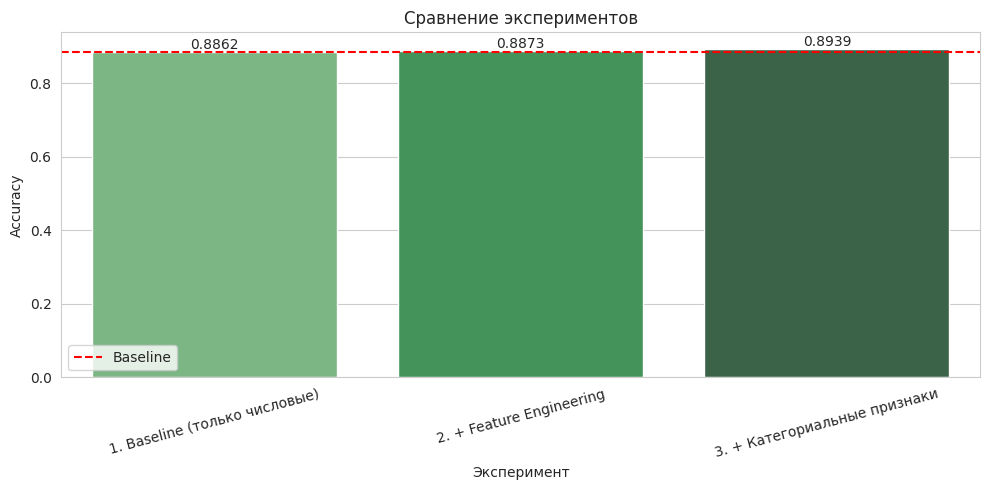

In [53]:
# Визуализация accuracy всех основных экспериментов
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=comparison,
    x='Эксперимент',
    y='Accuracy',
    hue='Эксперимент',
    palette='Greens_d',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.4f')

plt.axhline(
    results['baseline']['accuracy'],
    color='red',
    linestyle='--',
    label='Baseline'
)

plt.title('Сравнение экспериментов')
plt.ylabel('Accuracy')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()


### **9.3. Сформулируйте выводы**

---

> 📝 **Как отвечать на вопросы?** Дважды кликните на ячейку → впишите ответ → нажмите `Shift+Enter`

---



**Вопрос 1:** Какой accuracy показала baseline-модель?



**Ответ:** `Baseline-модель показала accuracy 0.886188, то есть примерно 88,62%`

**Вопрос 2:** Какие новые признаки вы создали? Помогли ли они улучшить результат?

**Ответ:**

Были созданы признаки наличия пропусков (job_unknown, education_unknown, contact_unknown, poutcome_unknown), а также was_contacted, has_positive_balance, has_any_loan и is_retired. После их добавления accuracy выросла с 0,8862 до 0,8873, то есть примерно на 0,11 процентного пункта. Улучшение есть, но оно незначительное.

Их смысл:
* _unknown — было ли исходное значение пропущено
* was_contacted — контактировали ли с клиентом ранее
* has_positive_balance — положительный ли баланс
* has_any_loan — есть ли ипотека или кредит
* is_retired — является ли клиент пенсионером






**Вопрос 3:** Помогло ли создание признаков из пропусков (`job_unknown` и т.д.)?


**Ответ:** `Совокупное улучшение accuracy составило только около 0,11 процентного пункта, поэтому существенного эффекта нет`

**Вопрос 4:** Какая модель показала лучший результат? На сколько она лучше baseline?


**Ответ:** `Лучший результат показала модель с добавлением категориальных признаков после One-Hot Encoding — accuracy 0.893923 (около 89,39%)`

**Вопрос 5:** Какие гипотезы из Части 4 подтвердились, а какие нет?


>**Критерии подтверждения гипотезы**
>
>| Результат | Интерпретация |
>|-----------|---------------|
>| Accuracy выросла на **≥ 0.5%** | ✅ Гипотеза подтвердилась, признак полезен |
>| Accuracy изменилась на **< 0.5%** | ⚠️ Эффект незначительный, нужны >дополнительные тесты |
>| Accuracy **упала** | ❌ Гипотеза не подтвердилась, признак не помогает (или мешает) |



**Ответ:** `Гипотеза о полезности категориальных признаков подтвердилась: после One-Hot Encoding accuracy выросла с 0,8862 до 0,8939, то есть примерно на 0,77. Гипотезы о полезности созданных признаков was_contacted, has_positive_balance, признаков пропусков и других Feature Engineering-признаков получили лишь слабое подтверждение: accuracy выросла примерно на 0,11, что по заданному критерию является незначительным эффектом`

> 💡 **Важно:** Даже если гипотеза не подтвердилась — это тоже результат! Отрицательный результат эксперимента — это знание о том, что **не** работает для данной задачи.


**Вопрос 6:** Что бы вы попробовали ещё, если бы было больше времени?


**Ответ:** `Отдельно протестировать влияние каждого нового признака, чтобы определить, какие из них действительно улучшают модель, попробовать другие способы обработки пропусков, настроить гиперпараметры модели и использовать дополнительные метрики, такие как precision, recall и F1-score, особенно с учётом сильного дисбаланса классов`





---

## **Дополнительные задания (выполняются по желанию)**

1. **Исследуйте признак `duration`**: Этот признак известен только после звонка (data leakage). Попробуйте обучить модель без него — насколько упадёт accuracy?


In [1]:
# ВАШ КОД

2. **Попробуйте использовать другие категориальные признаки**: Добавьте `month`, `poutcome` и посмотрите на результат.


In [2]:
# ВАШ КОД


3. **Попробуйте заполнение по группам**: Заполните пропуски в `education` не общей модой, а модой внутри группы по `job`. Улучшит ли это результат?


In [3]:
# ВАШ КОД

3. **Создайте составные признаки**: Например, `balance_per_age = balance / age` или `contacts_total = campaign + previous` и оцените их влияние на точность обученной модели.


In [4]:
# ВАШ КОД